# Diotic: overt and masked onsets, intensity-level control

Part of the per-condition split of `cortical_analysis.ipynb`; runs on its own.
Shared settings (models, fit parameters, ROI, peak windows, plot window) are in
`parameters.py`.

**Results come from the cluster.** Every fit and model test is computed and kept on the
cluster; this notebook only reads them and saves nothing. In the cluster's JupyterHub
(any browser, laptop closed) it reads them from the cluster's disk; on the Mac (VS Code or
Jupyter), open the connection once in a terminal with `bash cluster/connect.sh`. The
`check_results` cell below asks the cluster for anything missing by itself, waits for the job
and then carries on, so one Run All goes from start to finish (keep the computer awake). See `cluster/README.md`.

**Predictors are made as in Brodbeck et al. 2020** (`predictors/brodbeck2020_predictors.py`):
256-band gammatone spectrogram (20-5,000 Hz) scaled with exponent 0.6, edge-detector onsets,
overt/masked split at full frequency resolution and only then binned into 8 bands. Each speaker
is compared at its level in the mixture that was played (the speakers' own files are 4x louder).
The split is tested against the same onsets unsplit (`FULL_INMIX`). The other notebooks keep
the `gammatone_predictors.py` predictors.

**Model comparisons:** TFCE permutation tests within the ROI found in the clean notebook
(`roi.txt`, read by the `check_results` cell; `TEST_REGION` in `parameters.py`), as
Brodbeck et al. 2020 did for the two-talker conditions.

**Peaks:** each subject's peak is searched within +-25 ms of where that condition's
group-average waveform peaks inside the search window (`add_anchored_peak`).

**Per-bin TRF plots** (`plot_trf_bins`): one line per frequency bin in its own colour
with a band of +-1 SD across subjects (`BIN_ERROR` in `parameters.py`), the mean of
the bins as the thick black line, and the bins' centre frequencies on the right.

In [3]:
from parameters import *

In [4]:
# Checks that every result this notebook reads is on the cluster. If any are missing it
# asks the cluster for them, waits for the job (a line whenever its state changes) and
# carries on. Keep the computer awake while it waits.
check_results('diotic_overt_masked_onsets')

ROI from the clean notebook (18 sensors): AF3, F1, F3, F5, F7, FC5, FC3, C1, C3, C5, AF4, AFz, F6, FT8, FC6, FC4, FC2, C2
All 8 results this notebook reads are on the cluster.


In [5]:
# Your cluster jobs (PD = waiting for a slot, R = running).
cluster_queue()

          JOBID     USER      ACCOUNT           NAME  ST  TIME_LEFT NODES CPUS TRES_PER_N MIN_MEM NODELIST (REASON) 
        9352080     iggy def-ibruce_c cocktail-dioti   R 1-23:58:24     1   32        N/A    128G nc10314 (None) 



In [6]:
# The end of the latest cluster job's log (or cluster_log(<job number>)).
cluster_log()

== cocktail-diotic_overt_masked_onsets-9352080.out
INFO    :  *** BinauralCocktail initialized with root /lustre06/project/6005583/iggy/dataset/cocktail/bids on 2026-11-14 07:04:05 ***
INFO    :  Using eelbrain 0.0.0, mne 1.13.2.
INFO    :  *** BinauralCocktail initialized with root /lustre06/project/6005583/iggy/dataset/cocktail/bids on 2026-11-14 07:04:06 ***
INFO    :  Using eelbrain 0.0.0, mne 1.13.2.
  bad-channels file already exists for: 01, 02, 03, 04, 05, 06, 07, 08, 09, 10, 11, 12, 13. Skip all of them (default) or redo and overwrite all of them? [s/r]: s  (COCKTAIL_ANSWER)
  skipping (already done): 01, 02, 03, 04, 05, 06, 07, 08, 09, 10, 11, 12, 13

Done. Bad channels marked.
  ICA file already exists for: 01, 02, 03, 04, 05, 06, 07, 08, 09, 10, 11, 12, 13. Skip all of them (default) or redo and overwrite all of them? [s/r]: s  (COCKTAIL_ANSWER)
  skipping (already done): 01, 02, 03, 04, 05, 06, 07, 08, 09, 10, 11, 12, 13

Done. ICA fit and artifact components selected.
In-

## Diotic (overt onsets)

In [7]:
# The ROI this notebook uses, imported from roi.txt: the clean-speech notebook found it
# from its onset and envelope test - baseline topomaps.
ROI = show_roi('diotic_overt_masked_onsets')

ROI imported from roi.txt (~/projects/def-ibruce/iggy/dataset/cocktail/bids/derivatives/results/roi.txt), determined by the clean-speech notebook from its onset and envelope test - baseline topomaps (conjunction: significant for every predictor).
Used for every ROI test, STRF, TRF waveform and peak below.

ROI (18 sensors): AF3, F1, F3, F5, F7, FC5, FC3, C1, C3, C5, AF4, AFz, F6, FT8, FC6, FC4, FC2, C2


<small>

**Brodbeck et al. 2020: Two talkers, overt/masked split vs plain onsets**

- Splitting onsets into overt and masked improves the fit: t_max = 6.81, p < 0.001
- About 67% of onset magnitude is overt, 33% masked

</small>

In [ ]:
# Overt/masked split vs. plain onsets (diotic)
# overt/masked = the split of each speaker's onsets into the part still visible in the mixture and
# the part the other speaker covers, with the speaker at its level in the mixture.
# Brodbeck et al. 2020 ran this comparison too: splitting onsets into overt/masked significantly improved the model overall, t = 6.81, p < .001.

# FULL_INMIX  = Eatt + Oatt + Eign + Oign + Emix + Omix   (Oatt, Oign at their level in the mixture)
# FULL_MASKED = Eatt + Oatt_overt + Oatt_masked + Eign + Oign_overt + Oign_masked + Emix + Omix
#
# Comparison: FULL_MASKED > FULL_INMIX
#   (does splitting Oatt/Oign into overt + masked improve the fit? overt + masked == Oatt/Oign,
#   so the two models carry the same onsets, only split or not)
#
# Full predictor names (made as in Brodbeck et al. 2020, predictors/brodbeck2020_predictors.py):
# FULL_MASKED (test model):
#   gammatone-b20-8 + gammatone-b20-on-overt-8 + gammatone-b20-on-masked-8
#   + bg~gammatone-b20-8 + bg~gammatone-b20-on-overt-8 + bg~gammatone-b20-on-masked-8
#   + mix~gammatone-b20-8 + mix~gammatone-b20-on-8
#
# FULL_INMIX (baseline model):
#   gammatone-b20-8 + gammatone-b20-on-8
#   + bg~gammatone-b20-8 + bg~gammatone-b20-on-8
#   + mix~gammatone-b20-8 + mix~gammatone-b20-on-8

data, diff, result = compute_direct_comparison(FULL_MASKED, FULL_INMIX, 'diotic')
show_topomap_trio(data, diff, result, 'Overt/masked split vs. plain onsets', 'diotic', None)

In [9]:
display(result)
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Overt/masked split vs. plain onsets (diotic): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, tfce=True, p = 1.000>

Overt/masked split vs. plain onsets (diotic): ROI model comparison t(12) = -3.367, p = 0.9972


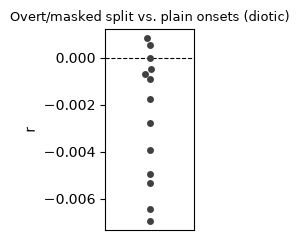

In [10]:
p = show_subject_swarm(diff, 'Overt/masked split vs. plain onsets', 'diotic')

In [11]:
# Loaded once here, reused by every STRF/peak/waveform/attention-
# effect/masking-comparison cell in both this subsection and "masked
# onset" below - same reasoning as data_full above, for FULL_MASKED.
data_masked = load_trfs_saved(FULL_MASKED, 'diotic')

<small>

**Brodbeck et al. 2020: Two talkers, overt onset attend unique contribution**

- Overt attended onsets: t_max = 3.34, p = 0.027 (weaker than masked)

</small>

Permutation test:   0%|          | 0/8191 [00:00<?, ? permutations/s]

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


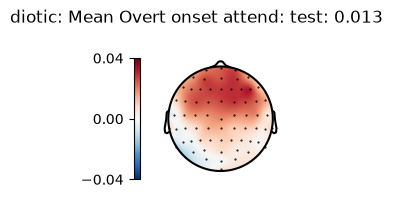

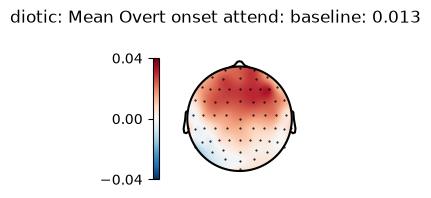

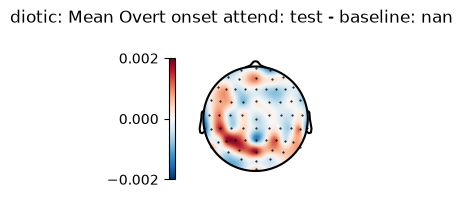

In [12]:
# Overt onset attend unique contribution (diotic)
# Brodbeck et al. 2020 ran this comparison too: attended overt onsets unique contribution, t = 3.34, p = .027.
data, diff, result = compute_unique_contribution(FULL_MASKED, overt_onset(ATTEND), 'diotic')
show_topomap_trio(data, diff, result, 'Overt onset attend', 'diotic', overt_onset(ATTEND))

In [13]:
display(result)
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Overt onset attend (diotic): ROI unique contribution t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, tfce=True, p = .321>

Overt onset attend (diotic): ROI unique contribution t(12) = 0.311, p = 0.3807


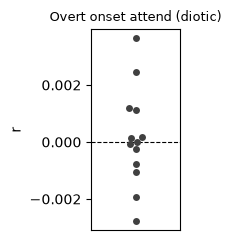

In [14]:
p = show_subject_swarm(diff, 'Overt onset attend', 'diotic')

<small>

**Brodbeck et al. 2020: Two talkers, overt onset ignore unique contribution**

- Overt ignored onsets: t_max = 3.82, p = 0.016 (weaker than masked)

</small>

Permutation test:   0%|          | 0/8191 [00:00<?, ? permutations/s]

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


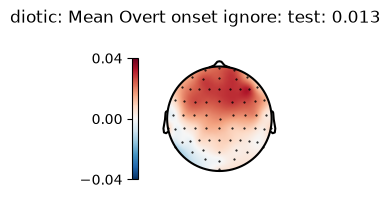

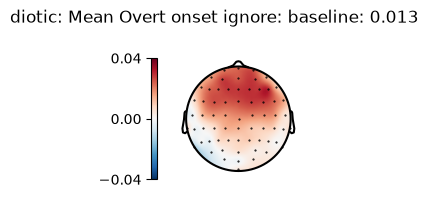

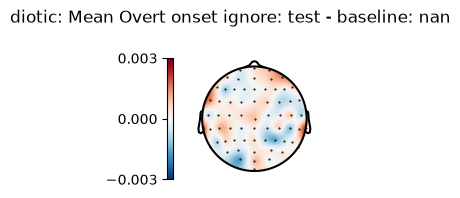

In [15]:
# Overt onset ignore unique contribution (diotic)
# Brodbeck et al. 2020 ran this comparison too: ignored overt onsets unique contribution, t = 3.82, p = .016.
data, diff, result = compute_unique_contribution(FULL_MASKED, overt_onset(IGNORE), 'diotic')
show_topomap_trio(data, diff, result, 'Overt onset ignore', 'diotic', overt_onset(IGNORE))

In [16]:
display(result)
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Overt onset ignore (diotic): ROI unique contribution t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, tfce=True, p = .790>

Overt onset ignore (diotic): ROI unique contribution t(12) = -0.066, p = 0.5257


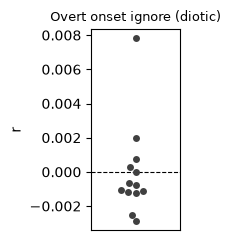

In [17]:
p = show_subject_swarm(diff, 'Overt onset ignore', 'diotic')

<small>

**Brodbeck et al. 2020: Two talkers, overt onset STRFs**

- Same positive-then-negative shape
- Early positive peak: not changed by attention (may even look bigger for ignored, because the attended negative peak starts early and overlaps it)
- Only the negative peak is changed by attention (attended only)

</small>

In [ ]:
# Overt onset attend STRF (diotic)
strf = extract_strf(data_masked, 'gammatone_b20_on_overt_8')
p = plot.Array(strf * 1e3, title='Overt onset attend STRF (diotic)', interpolation=STRF_INTERPOLATION, xlim=PLOT_WINDOW)

In [ ]:
# Overt onset ignore STRF (diotic)
strf = extract_strf(data_masked, 'bg_gammatone_b20_on_overt_8')
p = plot.Array(strf * 1e3, title='Overt onset ignore STRF (diotic)', interpolation=STRF_INTERPOLATION, xlim=PLOT_WINDOW)

<small>

**Brodbeck et al. 2020: Two talkers, overt onset peak latencies**

- Positive peak: attended 72 ms, ignored 83 ms (mixture 72 ms)
- Negative peak: attended 133 ms (mixture 138 ms)
- Peak search window: 20 to 250 ms for the overt/masked analysis (this notebook: 40 to 200 ms)

</small>

In [ ]:
# Overt onset attend peak amplitude & timing (diotic)
data = extract_trf(data_masked, 'gammatone_b20_on_overt_8')
data = add_anchored_peak(data, 'positive', ONSET_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', ONSET_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Overt onset attend (diotic) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Overt onset attend (diotic) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

In [ ]:
# Overt onset attend TRF per frequency bin (diotic)
p = plot_trf_bins(data_masked, 'gammatone_b20_on_overt_8', 'Overt onset attend TRF (diotic)')

In [ ]:
# Overt onset ignore peak amplitude & timing (diotic)
data = extract_trf(data_masked, 'bg_gammatone_b20_on_overt_8')
data = add_anchored_peak(data, 'positive', ONSET_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', ONSET_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Overt onset ignore (diotic) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Overt onset ignore (diotic) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

In [ ]:
# Overt onset ignore TRF per frequency bin (diotic)
p = plot_trf_bins(data_masked, 'bg_gammatone_b20_on_overt_8', 'Overt onset ignore TRF (diotic)')

In [ ]:
# Overt onset peak comparison across attend and ignore (diotic)
dss = []
for role_name, column in (('attend', 'gammatone_b20_on_overt_8'), ('ignore', 'bg_gammatone_b20_on_overt_8')):
    ds = extract_trf(data_masked, column)
    ds[:, 'role'] = role_name
    dss.append(ds)
data = combine(dss)
data = add_anchored_peak(data, 'positive', ONSET_POSITIVE_PEAK_WINDOW, kind='max', by='role')
data = add_anchored_peak(data, 'negative', ONSET_NEGATIVE_PEAK_WINDOW, kind='min', by='role')

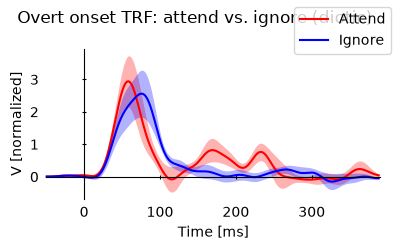

In [25]:
# The overt onset TRF waveform attend/ignore were each just measured
# from, overlaid so their shape and relative timing are visible
# directly, not just as extracted peak numbers below.
p = plot.UTSStat('trf_sm*1e3', 'role', data=data, frame='t', h=2.5, w=4, xlim=PLOT_WINDOW,
                  title='Overt onset TRF: attend vs. ignore (diotic)', labels={'attend': 'Attend', 'ignore': 'Ignore'}, colors={'attend': 'red', 'ignore': 'blue'})

In [26]:
print_peak_table(data, 'positive', 'role')
print_peak_table(data, 'negative', 'role')


positive peak
subject   role         time (ms)           amp
01        attend              70     2.412e-05
02        attend              54      0.006579
03        attend              45      0.001717
04        attend              64      0.003185
05        attend              46      0.004699
06        attend              43      0.003019
07        attend              80       0.00297
08        attend              60      0.001414
09        attend              56      0.005651
10        attend              68       0.01009
11        attend              62      0.007512
12        attend              70      0.001121
13        attend              82      0.001261
01        ignore              64     2.159e-06
02        ignore              74      0.001357
03        ignore              76      0.006997
04        ignore              54     0.0001777
05        ignore              76      0.007411
06        ignore              74     0.0008711
07        ignore              62      0.00137

In [27]:
display(test.pairwise('positive_time', 'role', match='subject', data=data, corr=False, title='overt onset positive peak latency: attend vs. ignore'))
display(test.pairwise('negative_time', 'role', match='subject', data=data, corr=False, title='overt onset negative peak latency: attend vs. ignore'))

,ignore
attend,t12 = -1.65 p = .124


,ignore
attend,t12 = -11.85*** p < .001


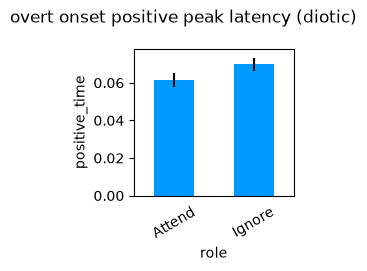

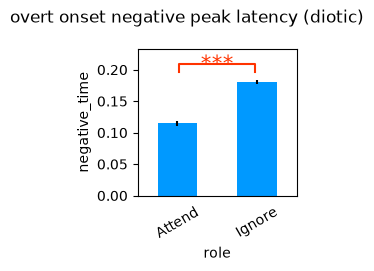

In [28]:
p = plot.Barplot('positive_time', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='overt onset positive peak latency (diotic)')
p.set_xtick_rotation(30)
p = plot.Barplot('negative_time', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='overt onset negative peak latency (diotic)')
p.set_xtick_rotation(30)

In [29]:
display(test.pairwise('positive_amp', 'role', match='subject', data=data, corr=False, title='overt onset positive peak amplitude: attend vs. ignore'))
display(test.pairwise('negative_amp', 'role', match='subject', data=data, corr=False, title='overt onset negative peak amplitude: attend vs. ignore'))

,ignore
attend,t12 = 0.78 p = .453


,ignore
attend,t12 = -0.56 p = .586


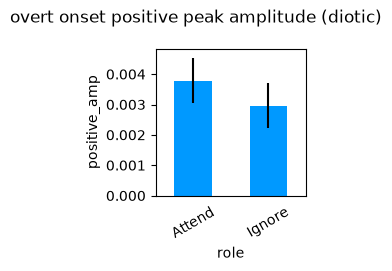

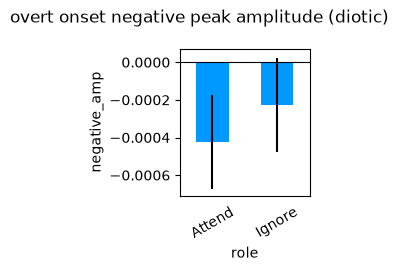

In [30]:
p = plot.Barplot('positive_amp', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='overt onset positive peak amplitude (diotic)')
p.set_xtick_rotation(30)
p = plot.Barplot('negative_amp', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='overt onset negative peak amplitude (diotic)')
p.set_xtick_rotation(30)

<small>

**Brodbeck et al. 2020: Two talkers, overt onset attention effect**

- No attention effect on the early positive peak
- Attention effect on the later negative peak, starting near the top of the positive peak

</small>

In [ ]:
# Overt onset attention effect: attend - ignore (diotic)
p = plot_trf_bins(data_masked, 'gammatone_b20_on_overt_8', 'Overt onset attention effect: attend - ignore (diotic)', subtract='bg_gammatone_b20_on_overt_8')

## Diotic (masked onset)

<small>

**Brodbeck et al. 2020: Two talkers, masked onset attend unique contribution**

- Masked attended onsets: t_max = 8.42, p < 0.001

</small>

Permutation test:   0%|          | 0/8191 [00:00<?, ? permutations/s]

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


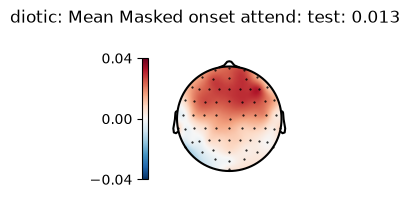

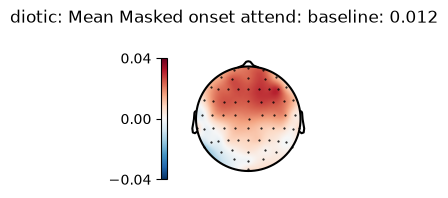

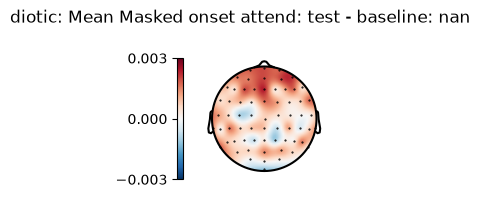

In [32]:
# Masked onset attend unique contribution (diotic)
# Brodbeck et al. 2020 ran this comparison too: attended masked onsets unique contribution, t = 8.42, p < .001 - the strongest of the four masking predictors.
data, diff, result = compute_unique_contribution(FULL_MASKED, masked_onset(ATTEND), 'diotic')
show_topomap_trio(data, diff, result, 'Masked onset attend', 'diotic', masked_onset(ATTEND))

In [33]:
display(result)
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Masked onset attend (diotic): ROI unique contribution t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, tfce=True, p = .073>

Masked onset attend (diotic): ROI unique contribution t(12) = 1.124, p = 0.1415


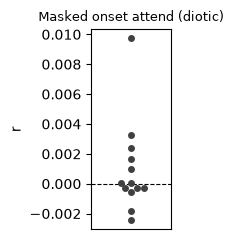

In [34]:
p = show_subject_swarm(diff, 'Masked onset attend', 'diotic')

<small>

**Brodbeck et al. 2020: Two talkers, masked onset ignore unique contribution**

- Masked ignored onsets: t_max = 5.23, p < 0.001
- Key finding: the brain recovers masked onsets even for the ignored speaker

</small>

Permutation test:   0%|          | 0/8191 [00:00<?, ? permutations/s]

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


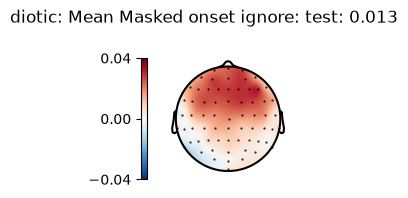

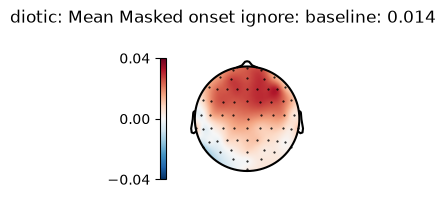

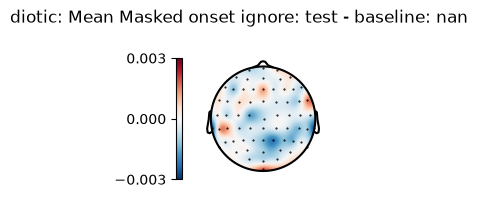

In [35]:
# Masked onset ignore unique contribution (diotic)
# Brodbeck et al. 2020 ran this comparison too: ignored masked onsets unique contribution, t = 5.23, p < .001 - the brain recovers masked information even for the ignored speaker.
data, diff, result = compute_unique_contribution(FULL_MASKED, masked_onset(IGNORE), 'diotic')
show_topomap_trio(data, diff, result, 'Masked onset ignore', 'diotic', masked_onset(IGNORE))

In [36]:
display(result)
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Masked onset ignore (diotic): ROI unique contribution t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, tfce=True, p = .257>

Masked onset ignore (diotic): ROI unique contribution t(12) = -0.646, p = 0.7349


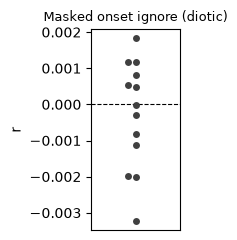

In [37]:
p = show_subject_swarm(diff, 'Masked onset ignore', 'diotic')

<small>

**Brodbeck et al. 2020: Two talkers, masked onset STRFs**

- Same positive-then-negative shape, but later than overt onsets
- Even the early positive peak is bigger for the attended speaker (an early attention effect)

</small>

In [ ]:
# Masked onset attend STRF (diotic)
strf = extract_strf(data_masked, 'gammatone_b20_on_masked_8')
p = plot.Array(strf * 1e3, title='Masked onset attend STRF (diotic)', interpolation=STRF_INTERPOLATION, xlim=PLOT_WINDOW)

In [ ]:
# Masked onset ignore STRF (diotic)
strf = extract_strf(data_masked, 'bg_gammatone_b20_on_masked_8')
p = plot.Array(strf * 1e3, title='Masked onset ignore STRF (diotic)', interpolation=STRF_INTERPOLATION, xlim=PLOT_WINDOW)

<small>

**Brodbeck et al. 2020: Two talkers, masked onset peak latencies**

- Positive peak: attended 91 ms, ignored 97 ms
- Negative peak: attended 182 ms
- Masked onsets lag overt onsets by at least 15 ms at each peak (about 20 ms on average)
- Peak search window: 20 to 250 ms (this notebook: 40 to 200 ms)

</small>

In [ ]:
# Masked onset attend peak amplitude & timing (diotic)
data = extract_trf(data_masked, 'gammatone_b20_on_masked_8')
data = add_anchored_peak(data, 'positive', MASKED_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', MASKED_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Masked onset attend (diotic) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Masked onset attend (diotic) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

In [ ]:
# Masked onset attend TRF per frequency bin (diotic)
p = plot_trf_bins(data_masked, 'gammatone_b20_on_masked_8', 'Masked onset attend TRF (diotic)')

In [ ]:
# Masked onset ignore peak amplitude & timing (diotic)
data = extract_trf(data_masked, 'bg_gammatone_b20_on_masked_8')
data = add_anchored_peak(data, 'positive', MASKED_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', MASKED_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Masked onset ignore (diotic) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Masked onset ignore (diotic) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

In [ ]:
# Masked onset ignore TRF per frequency bin (diotic)
p = plot_trf_bins(data_masked, 'bg_gammatone_b20_on_masked_8', 'Masked onset ignore TRF (diotic)')

In [ ]:
# Masked onset peak comparison across attend and ignore (diotic)
dss = []
for role_name, column in (('attend', 'gammatone_b20_on_masked_8'), ('ignore', 'bg_gammatone_b20_on_masked_8')):
    ds = extract_trf(data_masked, column)
    ds[:, 'role'] = role_name
    dss.append(ds)
data = combine(dss)
data = add_anchored_peak(data, 'positive', MASKED_POSITIVE_PEAK_WINDOW, kind='max', by='role')
data = add_anchored_peak(data, 'negative', MASKED_NEGATIVE_PEAK_WINDOW, kind='min', by='role')

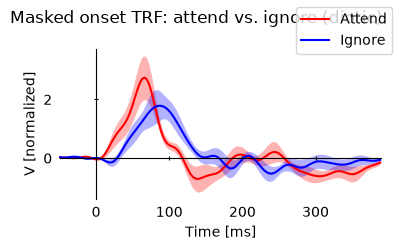

In [45]:
# The masked onset TRF waveform attend/ignore were each just measured
# from, overlaid so their shape and relative timing are visible
# directly, not just as extracted peak numbers below.
p = plot.UTSStat('trf_sm*1e3', 'role', data=data, frame='t', h=2.5, w=4, xlim=PLOT_WINDOW,
                  title='Masked onset TRF: attend vs. ignore (diotic)', labels={'attend': 'Attend', 'ignore': 'Ignore'}, colors={'attend': 'red', 'ignore': 'blue'})

In [46]:
print_peak_table(data, 'positive', 'role')
print_peak_table(data, 'negative', 'role')


positive peak
subject   role         time (ms)           amp
01        attend              54     1.213e-05
02        attend              66      0.007799
03        attend              58       0.00202
04        attend              43      0.004182
05        attend              60      0.007615
06        attend              56      0.001132
07        attend              89     0.0001165
08        attend              64      0.006133
09        attend              60      0.003116
10        attend              76      0.002096
11        attend              72      0.002275
12        attend              78      0.001786
13        attend              72      0.004868
01        ignore             111     8.378e-06
02        ignore             101      0.003596
03        ignore              82      0.004464
04        ignore             111     0.0006485
05        ignore              64      0.003452
06        ignore              64      0.001251
07        ignore              95     0.000628

In [47]:
display(test.pairwise('positive_time', 'role', match='subject', data=data, corr=False, title='masked onset positive peak latency: attend vs. ignore'))
display(test.pairwise('negative_time', 'role', match='subject', data=data, corr=False, title='masked onset negative peak latency: attend vs. ignore'))

,ignore
attend,t12 = -4.05** p = .002


,ignore
attend,t12 = -6.02*** p < .001


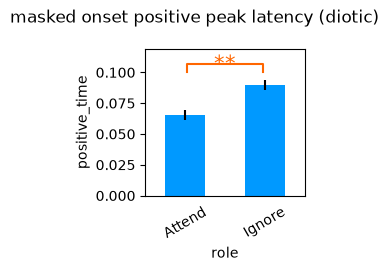

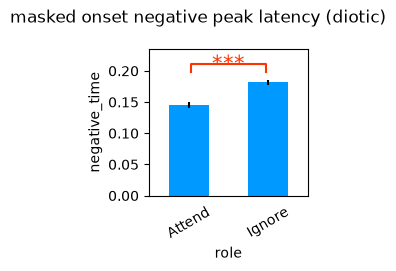

In [48]:
p = plot.Barplot('positive_time', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='masked onset positive peak latency (diotic)')
p.set_xtick_rotation(30)
p = plot.Barplot('negative_time', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='masked onset negative peak latency (diotic)')
p.set_xtick_rotation(30)

In [49]:
display(test.pairwise('positive_amp', 'role', match='subject', data=data, corr=False, title='masked onset positive peak amplitude: attend vs. ignore'))
display(test.pairwise('negative_amp', 'role', match='subject', data=data, corr=False, title='masked onset negative peak amplitude: attend vs. ignore'))

,ignore
attend,t12 = 0.78 p = .453


,ignore
attend,t12 = -1.13 p = .280


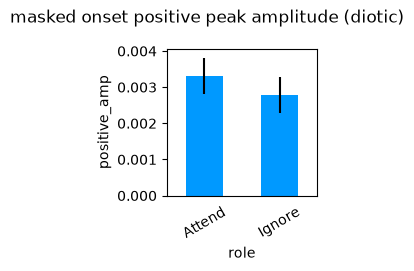

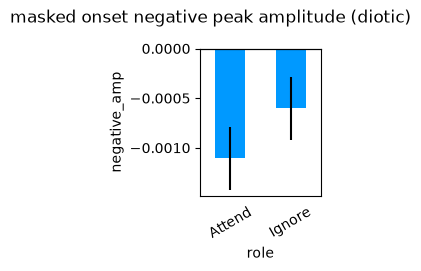

In [50]:
p = plot.Barplot('positive_amp', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='masked onset positive peak amplitude (diotic)')
p.set_xtick_rotation(30)
p = plot.Barplot('negative_amp', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='masked onset negative peak amplitude (diotic)')
p.set_xtick_rotation(30)

<small>

**Brodbeck et al. 2020: Two talkers, masked onset attention effect**

- Early positive peak bigger for attended than ignored, despite the following negative peak

</small>

In [ ]:
# Masked onset attention effect: attend - ignore (diotic)
p = plot_trf_bins(data_masked, 'gammatone_b20_on_masked_8', 'Masked onset attention effect: attend - ignore (diotic)', subtract='bg_gammatone_b20_on_masked_8')

<small>

**Brodbeck et al. 2020: Two talkers, overt vs masked peaks, attended**

- Positive peak later for masked: 91 vs 72 ms, t(25) = 2.85, p = 0.009
- Negative peak later for masked: 182 vs 133 ms, t(25) = 4.45, p < 0.001

</small>

In [ ]:
# Overt vs. masked peak comparison, attend (diotic)
# Brodbeck et al. 2020 ran this comparison too: attended overt 72ms vs. attended masked 91ms (t=2.85,p=.009); combined (not stream-split) late negative peak, overt 133ms vs. masked 182ms (t=4.45,p<.001).
dss = []
for masking, column in (('overt', 'gammatone_b20_on_overt_8'), ('masked', 'gammatone_b20_on_masked_8')):
    ds = extract_trf(data_masked, column)
    ds[:, 'masking'] = masking
    dss.append(ds)
data = combine(dss)
data = add_anchored_peak(data, 'positive', MASKED_POSITIVE_PEAK_WINDOW, kind='max', by='masking')
data = add_anchored_peak(data, 'negative', MASKED_NEGATIVE_PEAK_WINDOW, kind='min', by='masking')

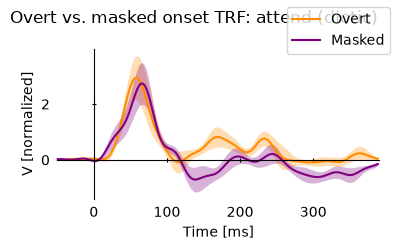

In [53]:
# Overt and masked onset TRFs of the attended speaker, overlaid
p = plot.UTSStat('trf_sm*1e3', 'masking', data=data, frame='t', h=2.5, w=4, xlim=PLOT_WINDOW,
                  title='Overt vs. masked onset TRF: attend (diotic)', labels=LABELS_MASKING, colors=COLORS_MASKING)

In [54]:
print_peak_table(data, 'positive', 'masking')
print_peak_table(data, 'negative', 'masking')


positive peak
subject   masking      time (ms)           amp
01        overt               70     2.412e-05
02        overt               54      0.006579
03        overt               45      0.001717
04        overt               64      0.003185
05        overt               46      0.004699
06        overt               43      0.003019
07        overt               80       0.00297
08        overt               60      0.001414
09        overt               56      0.005651
10        overt               68       0.01009
11        overt               62      0.007512
12        overt               70      0.001121
13        overt               82      0.001261
01        masked              54     1.213e-05
02        masked              66      0.007799
03        masked              58       0.00202
04        masked              43      0.004182
05        masked              60      0.007615
06        masked              56      0.001132
07        masked              89     0.000116

In [55]:
display(test.pairwise('positive_time', 'masking', match='subject', data=data, corr=False, title='attend positive peak latency: overt vs. masked'))
display(test.pairwise('negative_time', 'masking', match='subject', data=data, corr=False, title='attend negative peak latency: overt vs. masked'))

,masked
overt,t12 = -1.15 p = .272


,masked
overt,t12 = -5.19*** p < .001


In [56]:
display(test.pairwise('positive_amp', 'masking', match='subject', data=data, corr=False, title='attend positive peak amplitude: overt vs. masked'))
display(test.pairwise('negative_amp', 'masking', match='subject', data=data, corr=False, title='attend negative peak amplitude: overt vs. masked'))

,masked
overt,t12 = 0.47 p = .645


,masked
overt,t12 = 1.51 p = .158


<small>

**Brodbeck et al. 2020: Two talkers, overt vs masked peaks, ignored**

- Positive peak later for masked: 97 vs 83 ms, t(25) = 6.11, p < 0.001

</small>

In [ ]:
# Overt vs. masked peak comparison, ignore (diotic)
# Brodbeck et al. 2020 ran this comparison too: ignored overt 83ms vs. ignored masked 97ms (t=6.11,p<.001); combined (not stream-split) late negative peak, overt 133ms vs. masked 182ms (t=4.45,p<.001).
dss = []
for masking, column in (('overt', 'bg_gammatone_b20_on_overt_8'), ('masked', 'bg_gammatone_b20_on_masked_8')):
    ds = extract_trf(data_masked, column)
    ds[:, 'masking'] = masking
    dss.append(ds)
data = combine(dss)
data = add_anchored_peak(data, 'positive', MASKED_POSITIVE_PEAK_WINDOW, kind='max', by='masking')
data = add_anchored_peak(data, 'negative', MASKED_NEGATIVE_PEAK_WINDOW, kind='min', by='masking')

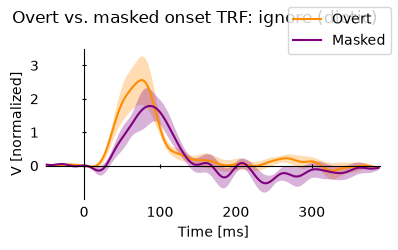

In [58]:
# Overt and masked onset TRFs of the ignored speaker, overlaid
p = plot.UTSStat('trf_sm*1e3', 'masking', data=data, frame='t', h=2.5, w=4, xlim=PLOT_WINDOW,
                  title='Overt vs. masked onset TRF: ignore (diotic)', labels=LABELS_MASKING, colors=COLORS_MASKING)

In [59]:
print_peak_table(data, 'positive', 'masking')
print_peak_table(data, 'negative', 'masking')


positive peak
subject   masking      time (ms)           amp
01        overt               64     2.159e-06
02        overt               74      0.001357
03        overt               76      0.006997
04        overt               54     0.0001777
05        overt               76      0.007411
06        overt               74     0.0008711
07        overt               62      0.001375
08        overt               54      0.005571
09        overt               78      0.006553
10        overt               70      0.002236
11        overt               72      0.002484
12        overt               88      0.002324
13        overt               66      0.001168
01        masked             111     8.378e-06
02        masked             101      0.003596
03        masked              82      0.004464
04        masked             111     0.0006485
05        masked              64      0.003452
06        masked              64      0.001251
07        masked              95     0.000628

In [60]:
display(test.pairwise('positive_time', 'masking', match='subject', data=data, corr=False, title='ignore positive peak latency: overt vs. masked'))
display(test.pairwise('negative_time', 'masking', match='subject', data=data, corr=False, title='ignore negative peak latency: overt vs. masked'))

,masked
overt,t12 = -3.42** p = .005


,masked
overt,t12 = -0.22 p = .828


In [61]:
display(test.pairwise('positive_amp', 'masking', match='subject', data=data, corr=False, title='ignore positive peak amplitude: overt vs. masked'))
display(test.pairwise('negative_amp', 'masking', match='subject', data=data, corr=False, title='ignore negative peak amplitude: overt vs. masked'))

,masked
overt,t12 = 0.31 p = .764


,masked
overt,t12 = 1.39 p = .189


<small>

**Brodbeck et al. 2020: Two talkers, stream x masking interaction**

- ANOVA on positive peak amplitude (attended/ignored x overt/masked): F(1,25) = 24.45, p < 0.001
- Overt onsets: no early attention effect; masked onsets: early attention effect

</small>

In [ ]:
# Stream x masking interaction on peak amplitude (diotic)
# Brodbeck et al. 2020 ran this comparison too: stream x masking interaction, F(1,25) = 24.45, p < .001 - overt onsets show no early attention effect, masked onsets do.
dss = []
for stream_name, is_attend in (('attend', True), ('ignore', False)):
    for masking_name in ('overt', 'masked'):
        prefix = '' if is_attend else 'bg_'
        column = f'{prefix}gammatone_b20_on_{masking_name}_8'
        ds = extract_trf(data_masked, column)
        ds[:, 'stream'] = stream_name
        ds[:, 'masking'] = masking_name
        dss.append(ds)
data = combine(dss)
data = add_anchored_peak(data, 'positive', MASKED_POSITIVE_PEAK_WINDOW, kind='max', by=('stream', 'masking'))
display(test.ANOVA('positive_amp', 'stream * masking * subject', data=data, title='stream x masking interaction (diotic)'))

## Diotic (intensity-level control)

### Overt and masked onsets together

Overt and masked onsets are made from the same syllable starts, so they rise and fall together. Removed one at a time (the tests above), each can stand in for the other, and both can look useless even when the speaker's onsets matter. Here both are removed at once: if the speaker's onsets add predictive power, this joint test should show it, as the unsplit onset does (the reference tests below, the same onsets unsplit, at the speaker's level in the mixture).

- Joint test significant, one-at-a-time tests not: the information is there, but overt and masked cannot be told apart in these data.
- Joint test not significant either: the overt/masked predictors carry less than the unsplit onsets.

In [ ]:
# Overt + masked onsets attend, together (diotic)
# both of the attended speaker's onset predictors removed at once
data, diff, result = compute_direct_comparison(FULL_MASKED, FULL_MASKED_NO_ATTEND_ONSETS, 'diotic')
show_topomap_trio(data, diff, result, 'Overt + masked onsets attend, together', 'diotic', None)

In [ ]:
display(result)
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Overt + masked onsets attend, together (diotic): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

In [ ]:
p = show_subject_swarm(diff, 'Overt + masked onsets attend, together', 'diotic')

In [ ]:
# Overt + masked onsets ignore, together (diotic)
# both of the ignored speaker's onset predictors removed at once
data, diff, result = compute_direct_comparison(FULL_MASKED, FULL_MASKED_NO_IGNORE_ONSETS, 'diotic')
show_topomap_trio(data, diff, result, 'Overt + masked onsets ignore, together', 'diotic', None)

In [ ]:
display(result)
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Overt + masked onsets ignore, together (diotic): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

In [ ]:
p = show_subject_swarm(diff, 'Overt + masked onsets ignore, together', 'diotic')

In [ ]:
# Onset attend at its level in the mixture (diotic)
# reference: the same onsets unsplit, removed from FULL_INMIX
data, diff, result = compute_direct_comparison(FULL_INMIX, FULL_INMIX_NO_ATTEND_ONSET, 'diotic')
show_topomap_trio(data, diff, result, 'Onset attend at its level in the mixture', 'diotic', None)

In [ ]:
display(result)
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Onset attend at its level in the mixture (diotic): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

In [ ]:
p = show_subject_swarm(diff, 'Onset attend at its level in the mixture', 'diotic')

In [ ]:
# Onset ignore at its level in the mixture (diotic)
# reference: the same onsets unsplit, removed from FULL_INMIX
data, diff, result = compute_direct_comparison(FULL_INMIX, FULL_INMIX_NO_IGNORE_ONSET, 'diotic')
show_topomap_trio(data, diff, result, 'Onset ignore at its level in the mixture', 'diotic', None)

In [ ]:
display(result)
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Onset ignore at its level in the mixture (diotic): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

In [ ]:
p = show_subject_swarm(diff, 'Onset ignore at its level in the mixture', 'diotic')

<small>

**Brodbeck et al. 2020: Two talkers, masked-aware vs level-aware model**

- The model that knows about the ignored speaker beats the loudness-tier model: t_max = 9.21, p < 0.001
- So the masked-onset effect is not just a response to quieter onsets

</small>

Permutation test:   0%|          | 0/8191 [00:00<?, ? permutations/s]

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


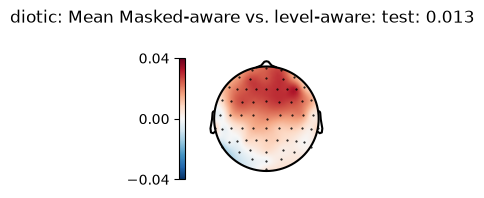

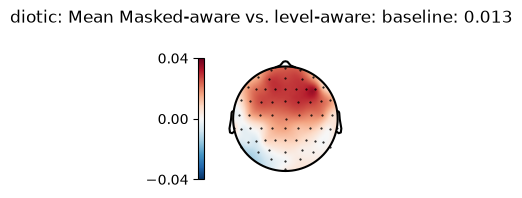

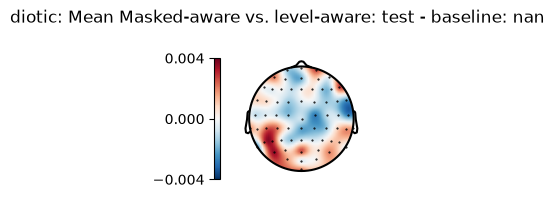

In [63]:
# Masked-aware vs. level-aware (diotic)
# Brodbeck et al. 2020 ran this comparison too: the ignored-speaker-aware model still beat the loudness-only model, t = 9.21, p < .001 - the masking effect isn't just about volume.
data, diff, result = compute_direct_comparison(FULL_MASKED, LEVEL_AWARE, 'diotic')
show_topomap_trio(data, diff, result, 'Masked-aware vs. level-aware', 'diotic', None)

In [64]:
display(result)
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Masked-aware vs. level-aware (diotic): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, tfce=True, p = .904>

Masked-aware vs. level-aware (diotic): ROI model comparison t(12) = -0.524, p = 0.6952


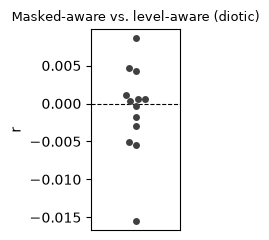

In [65]:
p = show_subject_swarm(diff, 'Masked-aware vs. level-aware', 'diotic')